# Notebook 1 — Python basics: summary of the first class and exercises

*Python for Instrumentation and Laboratory Experiments — Pr. T. Angot*

This notebook contains:
1. a summary of the first class,
2. the main notions of *A short course on Python* (variables, loops, conditions, functions),
3. my solutions to exercises 1 to 10 of the course.

Note: the course PDF uses `%pylab inline`, which is now deprecated. Here I import `numpy`, `matplotlib` and `scipy` explicitly, which is the recommended way today.

## 1. Summary of the first class

**Why Python for the lab?** It is free, open source, runs on Windows / macOS / Linux, and is used in real research environments (synchrotrons for example). It has a huge number of libraries:

| Library | Used for |
|---|---|
| `numpy` | arrays, maths functions |
| `matplotlib` | plots |
| `scipy` | integration, fits, ODEs (it uses the Fortran ODEPACK / LSODA solvers internally), FFT |
| `astropy` | astronomy tools |
| `pyserial` | talking to instruments through a serial port (RS232 / USB adapter) |
| `pyvisa` | talking to instruments through GPIB, USB, RS232 |

**Setting up:**
1. Install the Anaconda distribution (anaconda.com). It installs Python and the scientific libraries.
2. Open the *Anaconda prompt* (Windows search bar) and type `python` to test it.
3. Start a notebook with `jupyter notebook` and write code in cells. `Shift+Enter` runs a cell.
4. Extra packages: `conda install pyserial` (or `pip install pyserial`). `conda list` shows what is installed.

**Ways to run Python:**
- a script `myprogram.py` run with `python myprogram.py`,
- the interactive console (`>>>` prompt),
- **IPython** (`In [1]:` prompt): keeps the history, `?` for help, "magic" commands such as `%history`, `%psearch`, `%run`,
- **Jupyter notebook**: code + text (Markdown, LaTeX equations) + figures in one document. This is what we use in the course.

**Instruments and communication** (we will use these in the next sessions):
- `pyserial` lets us list the ports of the computer and see which cable is connected to which port, then send commands to an instrument.
- Other hardware mentioned: Arduino boards (Bluetooth for short range, LoRa for communication up to ~50 km), and the PicoScope (USB oscilloscope / signal generator).

## 2. Python basics (chapter 2 of the course)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate
from scipy.optimize import curve_fit
from scipy.integrate import odeint

### Numerical variables: int, float, complex

In [2]:
a = 3          # int
b = 3.         # float (the point makes it a real number)
z1 = 2.2 + 1.7j  # complex

print(type(a), type(b), type(z1))
print(3/7, 3./7.)  # in Python 3 both give a float (in Python 2, 3/7 gave 0)
print("real part:", z1.real, " imaginary part:", z1.imag, " conjugate:", z1.conjugate())
print("sin(z1) =", np.sin(z1))

<class 'int'> <class 'float'> <class 'complex'>
0.42857142857142855 0.42857142857142855
real part: 2.2  imaginary part: 1.7  conjugate: (2.2-1.7j)
sin(z1) = (2.286682876571396-1.5569573489096324j)


### Sequences: lists, tuples, dictionaries

In [3]:
leptons = ("electrons", "muons", "tauons")   # tuple: cannot be modified
print(leptons[0], leptons[2])

matr = [[2., 4.], [8., 16.]]                  # list of lists: can be modified
print(matr[0], matr[1][0])
matr[0][0] = 1.
print(matr)

const = {'cm-1': 8.066}                       # dictionary: key -> value
print("360 meV =", 360*const['cm-1'], "cm-1")
print(const.keys(), const.values(), const.items())

electrons tauons
[2.0, 4.0] 8.0
[[1.0, 4.0], [8.0, 16.0]]
360 meV = 2903.76 cm-1
dict_keys(['cm-1']) dict_values([8.066]) dict_items([('cm-1', 8.066)])


### Loops: `while` and `for`

In [4]:
# even numbers up to 10, with while
i = 2
while i <= 10:
    print(i, end=" ")
    i = i + 2
print()

# same thing with for and range(start, stop, step) -- stop is excluded
for i in range(2, 12, 2):
    print(i, end=" ")
print()

# same thing with a list comprehension, % is the modulo operator
print([i for i in range(0, 12) if i % 2 == 0])

# loops on real numbers with numpy
print(np.arange(3., 4., 0.1))
print(np.linspace(3., 4., 5))

2 4 6 8 10 
2 4 6 8 10 
[0, 2, 4, 6, 8, 10]
[3.  3.1 3.2 3.3 3.4 3.5 3.6 3.7 3.8 3.9]
[3.   3.25 3.5  3.75 4.  ]


### Conditions: `if`, `elif`, `else`

In [5]:
for x in [1, 2, 3]:
    if x == 2:
        print(x, "is equal to 2")
    elif x < 2:
        print(x, "is smaller than 2")
    else:
        print(x, "is greater than 2")

1 is smaller than 2
2 is equal to 2
3 is greater than 2


### Functions and procedures

Both are defined with `def`. A function returns a value with `return`, a procedure just does something (here print). The text between triple quotes is the docstring shown by `help()`.

(The course listing of `testracine` is missing the `:` after `if nb<0`, I fixed it.)

In [6]:
def distance(x0, y0, x1, y1):
    return np.sqrt((x1-x0)**2 + (y1-y0)**2)

def testracine(nb):
    """
    testracine(number) -> print the square root of a real number,
    or a message if the number is negative
    """
    if nb < 0:
        print("there is no real square root for", nb)
    else:
        print("the square root of", nb, "is", np.sqrt(nb))

print(distance(1, 2, 3, 4))
testracine(2)
testracine(-3)
help(testracine)

2.8284271247461903
the square root of 2 is 1.4142135623730951
there is no real square root for -3
Help on function testracine in module __main__:

testracine(nb)
    testracine(number) -> print the square root of a real number,
    or a message if the number is negative



## 3. Exercises

### Exercise 1 — Listing 1.1 in the Python console

In a terminal I start `python` and type the lines of Listing 1.1 one by one (no need to type the comments). After `plt.show()` a window opens with the figure.
`help(np.sin)` or `help(abs)` print the documentation of a function.

The same code in a notebook cell: it plots the intensity diffracted by a grating with $n=6$ slits, $\dfrac{\sin^2(\pi(n+1)x)}{\sin^2(\pi x)}$.

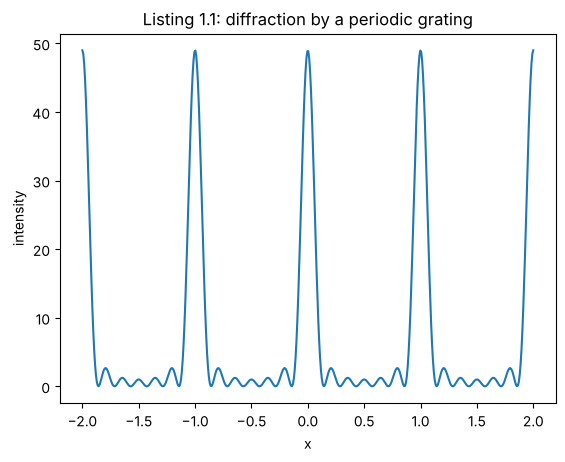

In [7]:
x = np.linspace(-2., 2., 500)
n = 6  # number of diffracting objects
fig = plt.figure()
plt.plot(x, np.sin(np.pi*(n+1)*x)**2/np.sin(np.pi*x)**2)
plt.xlabel("x")
plt.ylabel("intensity")
plt.title("Listing 1.1: diffraction by a periodic grating")
plt.show()

In [8]:
help(abs)

Help on built-in function abs in module builtins:

abs(x, /)
    Return the absolute value of the argument.



### Exercise 2 — same thing in IPython

In the terminal: `ipython`, then the same lines. Differences with the plain console:
- the prompt is `In [1]:` / `Out [1]:`, and old results can be reused (`Out[1]+6`),
- `np.sin?` replaces `help(np.sin)`,
- `%history` shows all the commands, `save mysavedhistory 1-5` saves lines 1 to 5 to a file, `%run mysavedhistory` executes them again.

### Exercise 3 — list the available objects

In IPython, `?*` (or `%psearch *`) lists all the objects of the namespace, and `%psearch a*` only the ones starting with "a". Then `object?` gives the documentation of each one.
In a notebook the same kind of search can be done with `dir()`:

In [9]:
# objects of numpy whose name starts with "lin"
print([name for name in dir(np) if name.startswith("lin")])

['linalg', 'linspace']


### Reading the data for exercises 4 and 5

The infrared spectrum of ethanol (gas phase) comes from the NIST webbook, in JCAMP-DX format (file `64-17-5-IR.jdx`).
The first 25 lines are a header. Each data line has 11 columns: the wavenumber of the first point, then 10 intensities spaced by 4 cm$^{-1}$. The last line `##END=` is skipped with `comments='##'`.

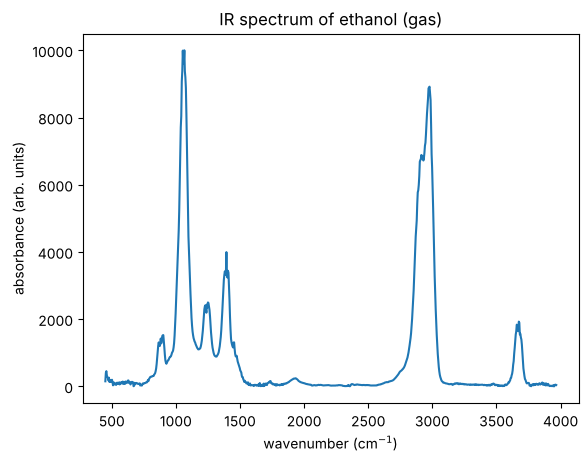

In [10]:
data = np.loadtxt('64-17-5-IR.jdx', unpack=True, skiprows=25, comments='##')

x = []; y = []
for i in range(0, len(data[0])):
    x.append(data[0][i])
    for j in range(1, 10):
        x.append(data[0][i] + 4*j)
    for j in range(1, 11):
        y.append(data[j][i])
x = np.array(x); y = np.array(y)

plt.plot(x, y)
plt.xlabel(r"wavenumber (cm$^{-1}$)")
plt.ylabel("absorbance (arb. units)")
plt.title("IR spectrum of ethanol (gas)")
plt.show()

### Course example: Gaussian fit of the peak between 3500 and 3800 cm$^{-1}$

$$G(x) = a\,\exp\!\left(-\frac{(x-x_0)^2}{2\sigma^2}\right)$$

**Remark on the width.** The course computes the FWHM with `2*sqrt(log1p(2))*sigma`. But `log1p(2)` is $\ln 3$, not what we want: for a Gaussian, the half maximum is reached when $(x-x_0)^2 = 2\sigma^2\ln 2$, so
$$\mathrm{FWHM} = 2\sqrt{2\ln 2}\,\sigma \approx 2.355\,\sigma .$$
I print both values to show the difference.

In [11]:
def trouveindex(valeur, x):
    # index of the first x >= valeur
    for index, nombre in enumerate(x):
        if nombre >= valeur:
            break
    return index

def gaussian(x, a, x0, sigma):
    return a*np.exp(-(x-x0)**2/(2.*sigma**2))

i1 = trouveindex(3500, x)
i2 = trouveindex(3800, x)
xp = x[i1:i2]
yp = y[i1:i2]

m = np.argmax(yp)
print('index =', m, '; coordinates = (', xp[m], ',', yp[m], ')')

bestval_g, covar_g = curve_fit(gaussian, xp, yp, p0=[yp[m], xp[m], 1])
fwhm_g = 2*np.sqrt(2*np.log(2))*abs(bestval_g[2])
print('Intensity =', bestval_g[0], ' Position =', bestval_g[1])
print('FWHM with the course formula 2*sqrt(log1p(2))*sigma =', 2*np.sqrt(np.log1p(2))*bestval_g[2])
print('FWHM correct, 2*sqrt(2 ln2)*sigma               =', fwhm_g)

index = 43 ; coordinates = ( 3674.0 , 1926.0 )
Intensity = 1874.6232963723583  Position = 3669.36038459505
FWHM with the course formula 2*sqrt(log1p(2))*sigma = 57.59683172202693
FWHM correct, 2*sqrt(2 ln2)*sigma               = 64.69997256960225


### Exercise 4 — Lorentzian fit, comparison with the Gaussian

The Lorentzian of the course, $\dfrac{2}{\pi\Gamma}\,\dfrac{1}{1+\left(\frac{x-x_0}{\Gamma/2}\right)^2}$, is normalised (area = 1). To fit a spectrum we need a free amplitude, so I use
$$L(x) = \frac{a}{1+\left(\frac{x-x_0}{\Gamma/2}\right)^2}$$
where $\Gamma$ is directly the FWHM.
To compare the two fits I compute the RMS of the residuals (data − fit).

Lorentzian: Intensity = 2003.2848854430233  Position = 3669.3360340914105  FWHM = 53.175821409611096
Gaussian  : Intensity = 1874.6232963723583  Position = 3669.36038459505  FWHM = 64.69997256960225
RMS of residuals: Gaussian = 63.46092268942853  Lorentzian = 131.15246631111916


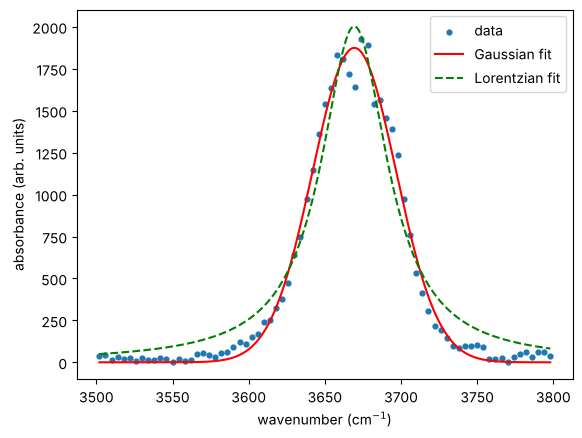

In [12]:
def lorentzian(x, a, x0, gamma):
    return a/(1 + ((x-x0)/(gamma/2))**2)

bestval_l, covar_l = curve_fit(lorentzian, xp, yp, p0=[yp[m], xp[m], 10])
print('Lorentzian: Intensity =', bestval_l[0], ' Position =', bestval_l[1], ' FWHM =', abs(bestval_l[2]))
print('Gaussian  : Intensity =', bestval_g[0], ' Position =', bestval_g[1], ' FWHM =', fwhm_g)

rms_g = np.sqrt(np.mean((yp - gaussian(xp, *bestval_g))**2))
rms_l = np.sqrt(np.mean((yp - lorentzian(xp, *bestval_l))**2))
print('RMS of residuals: Gaussian =', rms_g, ' Lorentzian =', rms_l)

xf = np.linspace(xp[0], xp[-1], 500)
plt.scatter(xp, yp, s=12, label='data')
plt.plot(xf, gaussian(xf, *bestval_g), 'r', label='Gaussian fit')
plt.plot(xf, lorentzian(xf, *bestval_l), 'g--', label='Lorentzian fit')
plt.xlabel(r"wavenumber (cm$^{-1}$)")
plt.ylabel("absorbance (arb. units)")
plt.legend()
plt.show()

**Comparison.** Both fits give the same position (≈ 3669 cm$^{-1}$, the O–H stretching of ethanol in the gas phase). The Gaussian follows the data better here (smaller residuals): the Lorentzian has tails that are too wide on both sides of the peak.

**Which one is "physical"?**
- A single isolated line broadened by the lifetime of the excited state (natural width) or by collisions has a **Lorentzian** shape. This is *homogeneous* broadening: every molecule has the same line.
- When the observed peak is the sum of many slightly shifted lines, the result is closer to a **Gaussian**. This is *inhomogeneous* broadening: Doppler effect, different environments, or here, the many unresolved rotational lines (P, Q, R branches) of the gas-phase vibration, measured with a 4 cm$^{-1}$ step.

So for a single line the Lorentzian is the physical shape, but this band is an envelope of many lines, which is why the Gaussian reproduces it better. A Voigt profile (convolution of the two) would be the most complete model.

### Exercise 5 — the two strongest peaks between 2500 and 3250 cm$^{-1}$

These are the C–H stretching bands. The two peaks overlap, so they must be fitted **simultaneously** with a sum of two functions (+ a constant background). I try two Gaussians and two Lorentzians.

Two Gaussians:
  peak 1: position = 2915.9 cm-1, FWHM = 116.3 cm-1
  peak 2: position = 2984.0 cm-1, FWHM = 59.4 cm-1
  RMS residuals = 136
Two Lorentzians:
  peak 1: position = 2906.8 cm-1, FWHM = 94.2 cm-1
  peak 2: position = 2977.1 cm-1, FWHM = 56.8 cm-1
  RMS residuals = 268
O-H peak of exercise 4 (Gaussian): FWHM = 64.7 cm-1


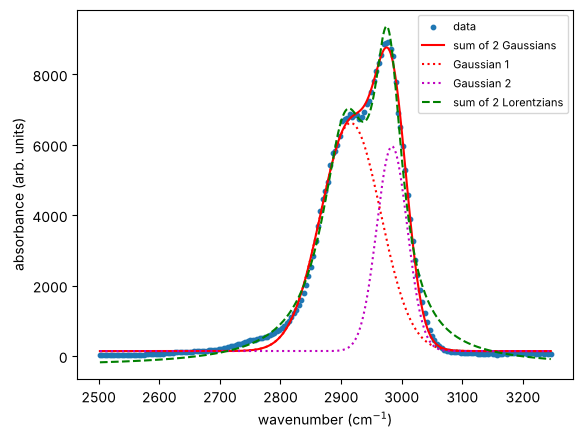

In [13]:
def two_gaussians(x, a1, x1, s1, a2, x2, s2, b):
    return gaussian(x, a1, x1, s1) + gaussian(x, a2, x2, s2) + b

def two_lorentzians(x, a1, x1, g1, a2, x2, g2, b):
    return lorentzian(x, a1, x1, g1) + lorentzian(x, a2, x2, g2) + b

i1 = trouveindex(2500, x)
i2 = trouveindex(3250, x)
xp2 = x[i1:i2]
yp2 = y[i1:i2]

# starting values read on the plot: peaks near 2914 and 2978 cm-1
p_g, cov_g = curve_fit(two_gaussians, xp2, yp2, p0=[6800, 2914, 20, 8900, 2978, 20, 0])
p_l, cov_l = curve_fit(two_lorentzians, xp2, yp2, p0=[6800, 2914, 40, 8900, 2978, 40, 0])

k = 2*np.sqrt(2*np.log(2))
print('Two Gaussians:')
print('  peak 1: position = %.1f cm-1, FWHM = %.1f cm-1' % (p_g[1], k*abs(p_g[2])))
print('  peak 2: position = %.1f cm-1, FWHM = %.1f cm-1' % (p_g[4], k*abs(p_g[5])))
print('  RMS residuals = %.0f' % np.sqrt(np.mean((yp2 - two_gaussians(xp2, *p_g))**2)))
print('Two Lorentzians:')
print('  peak 1: position = %.1f cm-1, FWHM = %.1f cm-1' % (p_l[1], abs(p_l[2])))
print('  peak 2: position = %.1f cm-1, FWHM = %.1f cm-1' % (p_l[4], abs(p_l[5])))
print('  RMS residuals = %.0f' % np.sqrt(np.mean((yp2 - two_lorentzians(xp2, *p_l))**2)))
print('O-H peak of exercise 4 (Gaussian): FWHM = %.1f cm-1' % fwhm_g)

xf = np.linspace(xp2[0], xp2[-1], 1000)
plt.scatter(xp2, yp2, s=10, label='data')
plt.plot(xf, two_gaussians(xf, *p_g), 'r', label='sum of 2 Gaussians')
plt.plot(xf, gaussian(xf, *p_g[0:3]) + p_g[6], 'r:', label='Gaussian 1')
plt.plot(xf, gaussian(xf, *p_g[3:6]) + p_g[6], 'm:', label='Gaussian 2')
plt.plot(xf, two_lorentzians(xf, *p_l), 'g--', label='sum of 2 Lorentzians')
plt.xlabel(r"wavenumber (cm$^{-1}$)")
plt.ylabel("absorbance (arb. units)")
plt.legend(fontsize=8)
plt.show()

**Comparison.** Again the sum of two Gaussians fits better than two Lorentzians. The peak at ≈ 2984 cm$^{-1}$ has a width comparable to the O–H peak of exercise 4 (≈ 60 cm$^{-1}$), while the peak at ≈ 2916 cm$^{-1}$ is about twice as wide (≈ 115 cm$^{-1}$). This is not surprising: in this region there are several C–H stretching modes (CH$_3$ and CH$_2$, symmetric and antisymmetric) that are not resolved, so the "peak" at lower wavenumber is actually several bands merged together.

### Exercise 6 — integral of $\sqrt{1-x^2}$ on $[0,1]$ with random numbers

We draw $n$ random points $(t, u)$ in the unit square and count the fraction that falls under the curve. This fraction estimates the area, which is a quarter of a disc: $\pi/4 \approx 0.7854$.
I use numpy arrays instead of the list comprehension of the course; it gives the same count but much faster.

In [14]:
def fn(t):
    return np.sqrt(1 - t**2)

rng = np.random.default_rng()
for i in range(1, 8):
    n = 10**i
    t = rng.random(n)
    u = rng.random(n)
    I = np.sum(u <= fn(t))/n
    print('I = %.7f   for n = %9d   error = %.1e' % (I, n, abs(I - np.pi/4)))
print('theory: pi/4 = %.7f' % (np.pi/4))

I = 0.8000000   for n =        10   error = 1.5e-02
I = 0.7500000   for n =       100   error = 3.5e-02
I = 0.7890000   for n =      1000   error = 3.6e-03
I = 0.7781000   for n =     10000   error = 7.3e-03
I = 0.7850800   for n =    100000   error = 3.2e-04


I = 0.7861190   for n =   1000000   error = 7.2e-04


I = 0.7855127   for n =  10000000   error = 1.1e-04
theory: pi/4 = 0.7853982


The error decreases like $1/\sqrt{n}$: we need 100 times more points to gain one digit. This method is slow but easy to use in many dimensions.

### Exercise 7 — same integral with `scipy.integrate.quad`

In [15]:
result = integrate.quad(fn, 0, 1)
print(result)  # (value, estimated error)
print('4 x integral =', 4*result[0])
print('pi           =', np.pi)

(0.7853981633974481, 8.833911380179416e-11)
4 x integral = 3.1415926535897922
pi           = 3.141592653589793


`quad` gives $\pi/4$ to machine precision instantly, so $4\int_0^1\sqrt{1-x^2}\,dx = \pi$.

### Exercise 8 — derivative of $\sin(x)$ on $[0,10]$

The course uses `scipy.misc.derivative`, which has been **removed** from recent versions of scipy. I use instead:
- my own central difference: $f'(x) \approx \dfrac{f(x+h)-f(x-h)}{2h}$,
- `np.gradient`, which does the same on an array of values.

max |central difference - cos| = 5.4940496596600497e-11
max |np.gradient       - cos| = 0.0027087931808766896


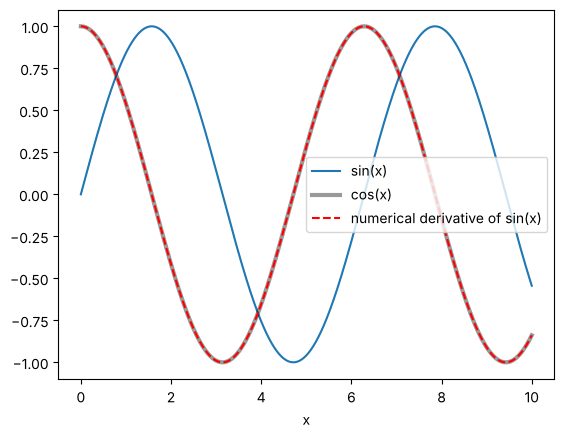

In [16]:
def derivative(f, x, h=1e-5):
    return (f(x+h) - f(x-h))/(2*h)

x = np.linspace(0, 10, 1000)
d1 = derivative(np.sin, x)
d2 = np.gradient(np.sin(x), x)

print('max |central difference - cos| =', np.max(np.abs(d1 - np.cos(x))))
print('max |np.gradient       - cos| =', np.max(np.abs(d2 - np.cos(x))))

plt.plot(x, np.sin(x), label='sin(x)')
plt.plot(x, np.cos(x), 'k', lw=3, alpha=0.4, label='cos(x)')
plt.plot(x, d1, 'r--', label='numerical derivative of sin(x)')
plt.xlabel('x')
plt.legend()
plt.show()

The numerical derivative is on top of $\cos(x)$; the difference is ~$10^{-10}$ for the central difference (tiny step $h=10^{-5}$) and ~$10^{-3}$ for `np.gradient` (the step is the grid spacing, 0.01, and the formula is less precise at the two ends).

### Exercise 9 — two coupled harmonic oscillators

Two masses $m$, each attached to a wall by a spring $k$, and connected to each other by a coupling spring $k_c$:

$$m\ddot x_1 = -k x_1 - k_c (x_1 - x_2), \qquad m\ddot x_2 = -k x_2 - k_c (x_2 - x_1)$$

`odeint` solves first-order equations, so the state is $Y = [x_1, v_1, x_2, v_2]$ and the function returns the velocities and accelerations.
Initial conditions: mass 1 moved by $x_1 = 1$, mass 2 at rest at $x_2 = 0$, no initial velocity.

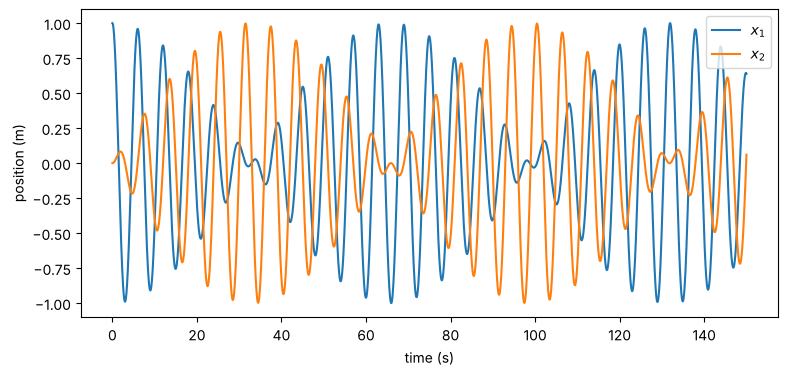

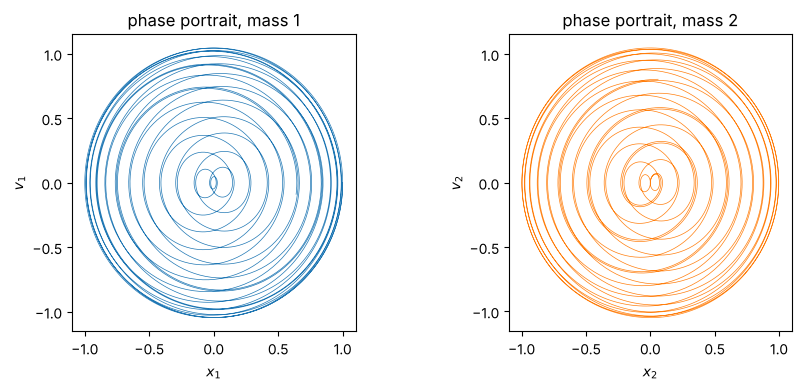

normal modes: w1 = 1.000 rad/s (in phase), w2 = 1.095 rad/s (opposite phase)
energy exchange period 2*pi/(w2-w1) = 65.8 s


In [17]:
m = 1.0    # kg
k = 1.0    # N/m
kc = 0.1   # N/m, weak coupling

def deriv(Y, t):
    x1, v1, x2, v2 = Y
    a1 = (-k*x1 - kc*(x1 - x2))/m
    a2 = (-k*x2 - kc*(x2 - x1))/m
    return [v1, a1, v2, a2]

Y0 = [1.0, 0.0, 0.0, 0.0]   # initial conditions [x1, v1, x2, v2]
t = np.linspace(0, 150, 5000)
res = odeint(deriv, Y0, t)
x1, v1, x2, v2 = res[:, 0], res[:, 1], res[:, 2], res[:, 3]

plt.figure(figsize=(9, 4))
plt.plot(t, x1, label='$x_1$')
plt.plot(t, x2, label='$x_2$')
plt.xlabel('time (s)')
plt.ylabel('position (m)')
plt.legend()
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))
ax1.plot(x1, v1, lw=0.5); ax1.set_xlabel('$x_1$'); ax1.set_ylabel('$v_1$'); ax1.set_title('phase portrait, mass 1')
ax2.plot(x2, v2, lw=0.5, color='C1'); ax2.set_xlabel('$x_2$'); ax2.set_ylabel('$v_2$'); ax2.set_title('phase portrait, mass 2')
for ax in (ax1, ax2):
    ax.set_aspect('equal')
plt.tight_layout()
plt.show()

w1 = np.sqrt(k/m)
w2 = np.sqrt((k + 2*kc)/m)
print('normal modes: w1 = %.3f rad/s (in phase), w2 = %.3f rad/s (opposite phase)' % (w1, w2))
print('energy exchange period 2*pi/(w2-w1) = %.1f s' % (2*np.pi/(w2 - w1)))

**Interpretation.** The energy goes back and forth between the two masses (beats): when mass 1 stops, mass 2 oscillates with the full amplitude, and the other way round. The motion is the sum of the two normal modes ($x_1 = x_2$ at $\omega_1=\sqrt{k/m}$ and $x_1=-x_2$ at $\omega_2=\sqrt{(k+2k_c)/m}$), and the exchange period $2\pi/(\omega_2-\omega_1)$ (≈ 66 s here) matches the plot.
In the phase portraits the trajectory is not a single ellipse, as it would be for one free oscillator: the radius grows and shrinks as the energy of each mass changes, so the curve fills a disc.

### Exercise 10 — inverse Fourier transform of a cardinal sine

$\mathrm{sinc}(x) = \dfrac{\sin(\pi x)}{\pi x}$ (this is the definition used by `np.sinc`). Between −1 and 1, `np.sinc(x)` only shows the central lobe, so I use $\mathrm{sinc}(a x)$ with $a=40$ to see several oscillations.
`np.fft.ifft` expects the point $x=0$ at index 0, so I use `ifftshift` before the transform and `fftshift` after it to put the zero frequency back in the middle.

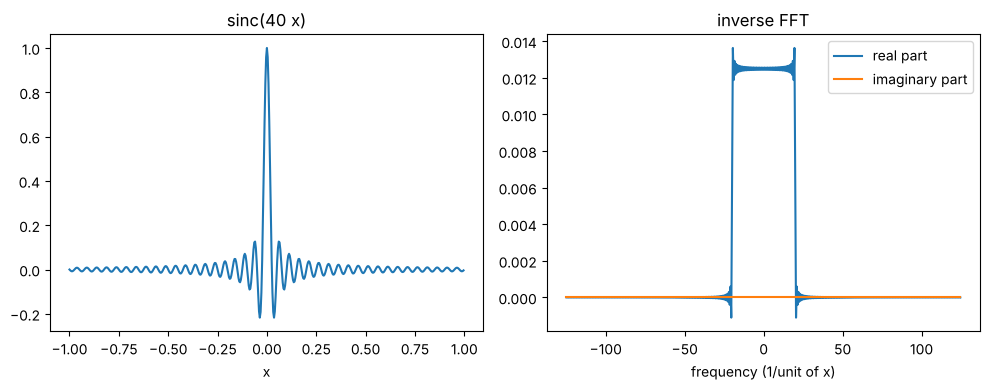

the rectangle goes from -19.5 to 19.5, total width = 39.0 (expected about a = 40, limited by the frequency step)


In [18]:
N = 500
x = np.linspace(-1, 1, N, endpoint=False)
dx = x[1] - x[0]
a = 40
s = np.sinc(a*x)

S = np.fft.fftshift(np.fft.ifft(np.fft.ifftshift(s)))
f = np.fft.fftshift(np.fft.fftfreq(N, d=dx))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(x, s)
ax1.set_xlabel('x'); ax1.set_title('sinc(40 x)')
ax2.plot(f, S.real, label='real part')
ax2.plot(f, S.imag, label='imaginary part')
ax2.set_xlabel('frequency (1/unit of x)'); ax2.set_title('inverse FFT')
ax2.legend()
plt.tight_layout()
plt.show()

width = f[np.abs(S.real) > 0.5*np.max(S.real)]
print('the rectangle goes from %.1f to %.1f, total width = %.1f (expected about a = %d, limited by the frequency step)' % (width[0], width[-1], width[-1]-width[0], a))

**Result.** The inverse Fourier transform of a cardinal sine is a **rectangle function** (top hat): constant between $-a/2$ and $a/2$, zero outside, and the imaginary part is zero because the sinc is even. The small oscillations at the edges come from the fact that the sinc is cut at $x=\pm1$ (Gibbs phenomenon).
This is the reverse of a well-known result in optics: the diffraction pattern of a single slit (a rectangle) is a sinc$^2$.